###**Data Preparation and Descriptive Analysis**

In [10]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

file_path = '/content/sample_data/world-happiness-report-2021.csv'
df = pd.read_csv(file_path)

# Seven Variables
vars_of_interest = [
    'Ladder score',
    'Logged GDP per capita',
    'Social support',
    'Healthy life expectancy',
    'Freedom to make life choices',
    'Generosity',
    'Perceptions of corruption'
]
sub_df = df[vars_of_interest]

In [11]:
n_obs = len(sub_df)
print(f"Number of observations: {n_obs}")

desc_stats = sub_df.describe().T[['mean', 'std']].round(3)
print("\n--- Summary Statistics ---")
print(desc_stats)

Number of observations: 149

--- Summary Statistics ---
                                mean    std
Ladder score                   5.533  1.074
Logged GDP per capita          9.432  1.159
Social support                 0.815  0.115
Healthy life expectancy       64.993  6.762
Freedom to make life choices   0.792  0.113
Generosity                    -0.015  0.151
Perceptions of corruption      0.727  0.179


**Explain why the variables should be standardized before conducting PCA.**
* Principal Component Analysis (PCA) relies on finding directions of maximum variance within the feature space. Variables measured on vastly different scales will unduly dominate the principal components simply because of their larger numeric variance.

* For example, Healthy life expectancy ranges around 65 years with a standard deviation of 6.762, whereas Social support consists of proportions near 0.815 with a standard deviation of 0.115. Without standardization ($Z$-score transformation), PCA performed on the raw covariance matrix would treat Healthy life expectancy as nearly fifty times more important than Social support. Standardizing standardizes each variable to mean 0 and variance 1, placing all dimensions on an equal mathematical footprint so the PCA reflects real linear relationships rather than measurement units.

In [12]:
# Correlation Matrix
corr_matrix = sub_df.corr().round(3)
print("\n--- Correlation Matrix ---")
print(corr_matrix)


--- Correlation Matrix ---
                              Ladder score  Logged GDP per capita  \
Ladder score                         1.000                  0.790   
Logged GDP per capita                0.790                  1.000   
Social support                       0.757                  0.785   
Healthy life expectancy              0.768                  0.859   
Freedom to make life choices         0.608                  0.432   
Generosity                          -0.018                 -0.199   
Perceptions of corruption           -0.421                 -0.342   

                              Social support  Healthy life expectancy  \
Ladder score                           0.757                    0.768   
Logged GDP per capita                  0.785                    0.859   
Social support                         1.000                    0.723   
Healthy life expectancy                0.723                    1.000   
Freedom to make life choices           0.483          

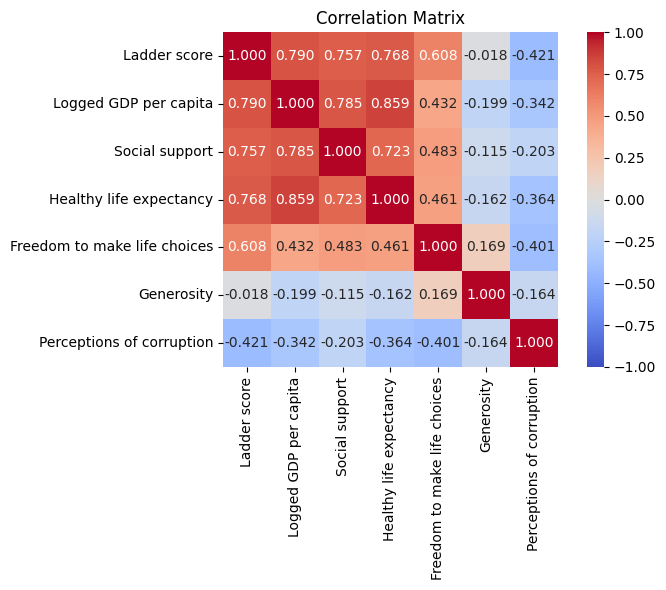

In [13]:
# Heatmap Visualization
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix", fontsize=12)
plt.tight_layout()
plt.show()

The Ladder score and Perceptions of corruption ($r = -0.421$): they demonstrates a moderate negative relationship. The higher perceived institutional corruption is consistently associated with lower overall subjective well-being.

###**Principal Component Analysis**

In [15]:
from sklearn.preprocessing import StandardScaler

# Define the input features X
X = sub_df

# Standardize variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Conduct PCA via Eigen-decomposition of correlation matrix
corr_matrix = np.corrcoef(X_scaled, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eig(corr_matrix)

# Sort eigenvalues & eigenvectors
idx = eigenvalues.argsort()[::-1]
eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print("PCA using correlation matrix successfully conducted.")

PCA using correlation matrix successfully conducted.


In [16]:
p = len(vars_of_interest)

eigenvalues_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(p)],
    'Eigenvalue': eigenvalues
}).round(3)

print("--- Eigenvalues of the 7 Principal Components ---")
print(eigenvalues_df.to_string(index=False))

--- Eigenvalues of the 7 Principal Components ---
Principal Component  Eigenvalue
                PC1       3.914
                PC2       1.289
                PC3       0.708
                PC4       0.518
                PC5       0.251
                PC6       0.193
                PC7       0.126


In [17]:
prop_var = eigenvalues / p

prop_var_df = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(p)],
    'Eigenvalue': eigenvalues,
    'Proportion of Variance Explained': prop_var
}).round(3)

print("--- Proportion of Variance Explained ---")
print(prop_var_df.to_string(index=False))

--- Proportion of Variance Explained ---
Principal Component  Eigenvalue  Proportion of Variance Explained
                PC1       3.914                             0.559
                PC2       1.289                             0.184
                PC3       0.708                             0.101
                PC4       0.518                             0.074
                PC5       0.251                             0.036
                PC6       0.193                             0.028
                PC7       0.126                             0.018


In [19]:
# Cumulative proportion of variance
cum_prop_var = np.cumsum(prop_var)

pca_summary_table = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(p)],
    'Eigenvalue': eigenvalues,
    'Proportion of Variance': prop_var,
    'Cumulative Proportion': cum_prop_var
}).round(3)

print("--- Complete Variance Summary Table ---")
print(pca_summary_table.to_string(index=False))

--- Complete Variance Summary Table ---
Principal Component  Eigenvalue  Proportion of Variance  Cumulative Proportion
                PC1       3.914                   0.559                  0.559
                PC2       1.289                   0.184                  0.743
                PC3       0.708                   0.101                  0.844
                PC4       0.518                   0.074                  0.918
                PC5       0.251                   0.036                  0.954
                PC6       0.193                   0.028                  0.982
                PC7       0.126                   0.018                  1.000


In [20]:
# Eigenvectors/component coefficients for the retained components
retained_components = eigenvectors[:, :2]

loadings_df = pd.DataFrame(
    retained_components,
    index=vars_of_interest,
    columns=['PC1', 'PC2']
).round(3)

print("--- Eigenvectors / Component Coefficients (PC1 and PC2) ---")
print(loadings_df)

--- Eigenvectors / Component Coefficients (PC1 and PC2) ---
                                PC1    PC2
Ladder score                  0.464  0.040
Logged GDP per capita         0.459 -0.197
Social support                0.433 -0.163
Healthy life expectancy       0.453 -0.146
Freedom to make life choices  0.341  0.365
Generosity                   -0.042  0.753
Perceptions of corruption    -0.252 -0.460


In [21]:
# Variables have the largest absolute coefficients in PC1
pc1_coefficients = loadings_df[['PC1']].copy()
pc1_coefficients['Absolute Coefficient'] = pc1_coefficients['PC1'].abs()

# Absolute coefficient magnitude
pc1_sorted = pc1_coefficients.sort_values(by='Absolute Coefficient', ascending=False)

print("--- Variables Ranked by Absolute Coefficient in PC1 ---")
print(pc1_sorted.round(3))

--- Variables Ranked by Absolute Coefficient in PC1 ---
                                PC1  Absolute Coefficient
Ladder score                  0.464                 0.464
Logged GDP per capita         0.459                 0.459
Healthy life expectancy       0.453                 0.453
Social support                0.433                 0.433
Freedom to make life choices  0.341                 0.341
Perceptions of corruption    -0.252                 0.252
Generosity                   -0.042                 0.042


PC1 functions as an overarching index of Socioeconomic Prosperity and General Well-Being.

The four primary socio-economic variables all exhibit strong positive coefficients (ranging around $0.433 - 0.464$). This indicates that countries scoring high on PC1 simultaneously experience high national subjective well-being (**Ladder score**), strong economic performance (**Logged GDP per capita**), high health infrastructure (**Healthy life expectancy**), and strong social safety nets (**Social support**).

Conversely, Perceptions of corruption carries a negative coefficient ($-0.252$), demonstrating that institutional decay moves inversely to this core prosperity dimension.

###**Determining the Number of Component**

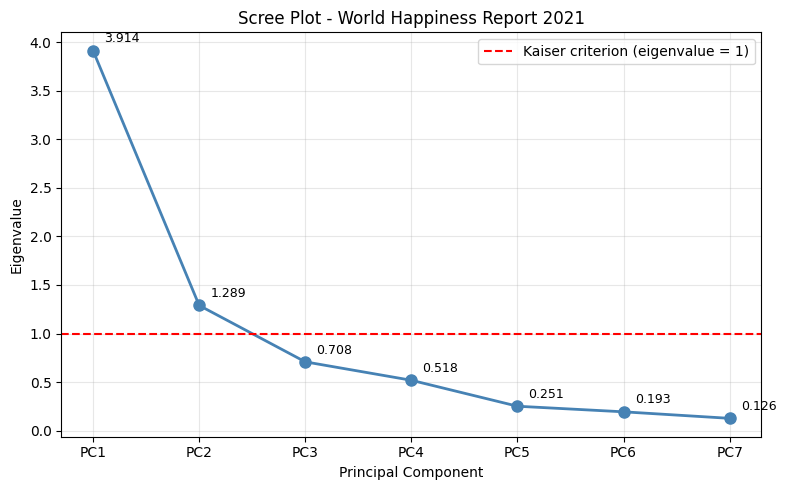

In [27]:
# Scree plot

pcs = np.arange(1, p + 1)

plt.figure(figsize=(8, 5))
plt.plot(pcs, eigenvalues, 'o-', color='steelblue', linewidth=2, markersize=8)
plt.axhline(y=1, color='red', linestyle='--', label='Kaiser criterion (eigenvalue = 1)')
for x, y in zip(pcs, eigenvalues):
    plt.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(8, 6), fontsize=9)
plt.xticks(pcs, [f'PC{i}' for i in pcs])
plt.xlabel('Principal Component')
plt.ylabel('Eigenvalue')
plt.title('Scree Plot - World Happiness Report 2021')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# Elbow

drops = eigenvalues[:-1] - eigenvalues[1:]
drop_df = pd.DataFrame({
    'From': [f'PC{i}' for i in range(1, p)],
    'To': [f'PC{i+1}' for i in range(1, p)],
    'Drop in Eigenvalue': drops
}).round(3)
print(drop_df.to_string(index=False))

bend = drops[:-1] - drops[1:]
elbow_pc = int(np.argmax(bend)) + 2
print(f"\nApparent elbow at PC{elbow_pc}")

From  To  Drop in Eigenvalue
 PC1 PC2               2.624
 PC2 PC3               0.581
 PC3 PC4               0.190
 PC4 PC5               0.267
 PC5 PC6               0.058
 PC6 PC7               0.067

Apparent elbow at PC2


In [29]:
# Kaiser criterion

kaiser_df = pca_summary_table.copy()
kaiser_df['Eigenvalue > 1?'] = np.where(eigenvalues > 1, 'Yes', 'No')
print(kaiser_df.to_string(index=False))

n_kaiser = int((eigenvalues > 1).sum())
print(f"\nKaiser criterion retains {n_kaiser} component(s): "
      + ", ".join(f"PC{i+1} ({eigenvalues[i]:.3f})" for i in range(n_kaiser)))

Principal Component  Eigenvalue  Proportion of Variance  Cumulative Proportion Eigenvalue > 1?
                PC1       3.914                   0.559                  0.559             Yes
                PC2       1.289                   0.184                  0.743             Yes
                PC3       0.708                   0.101                  0.844              No
                PC4       0.518                   0.074                  0.918              No
                PC5       0.251                   0.036                  0.954              No
                PC6       0.193                   0.028                  0.982              No
                PC7       0.126                   0.018                  1.000              No

Kaiser criterion retains 2 component(s): PC1 (3.914), PC2 (1.289)


Retain 1 PC(s): cumulative variance = 0.559
Retain 2 PC(s): cumulative variance = 0.743
Retain 3 PC(s): cumulative variance = 0.844
Retain 4 PC(s): cumulative variance = 0.918
Retain 5 PC(s): cumulative variance = 0.954
Retain 6 PC(s): cumulative variance = 0.982
Retain 7 PC(s): cumulative variance = 1.000


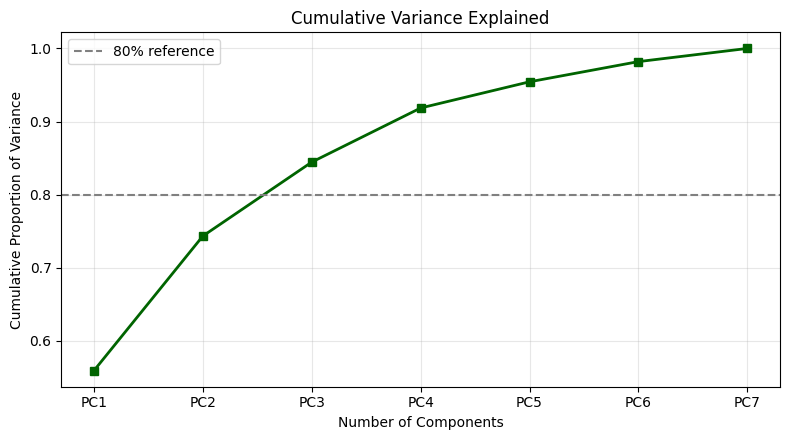

In [30]:
for k in range(1, p + 1):
    print(f"Retain {k} PC(s): cumulative variance = {cum_prop_var[k-1]:.3f}")

plt.figure(figsize=(8, 4.5))
plt.plot(pcs, cum_prop_var, 's-', color='darkgreen', linewidth=2)
plt.axhline(0.80, color='gray', linestyle='--', label='80% reference')
plt.xticks(pcs, [f'PC{i}' for i in pcs])
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Proportion of Variance')
plt.title('Cumulative Variance Explained')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Retain 2 components, which together explain 74.3% of the variance. The elbow and Kaiser agree. PC3 would raise the total to 84.4%, but its eigenvalue is 0.708 and it adds only 10.1%.

5. Briefly explain why the number of components retained should not be determined using only one criterion.

\
Using only one criterion is not enough because each has a weakness: the elbow is subjective, the Kaiser cutoff of 1 is arbitrary, and a variance threshold depends on a chosen percentage. In this dataset the elbow and Kaiser agree on 2 components, but an 80% threshold would suggest 3. Combining eigenvalue size, cumulative variance and interpretability gives a more reliable decision.

###**Interpretation of Principal Components**

In [35]:
loadings = pd.DataFrame(
    eigenvectors[:, :2],
    index=vars_of_interest,
    columns=['PC1', 'PC2']
).round(3)

print("PC1 (sorted by absolute coefficient)")
print(loadings['PC1'].reindex(loadings['PC1'].abs().sort_values(ascending=False).index))

print("\nPC2 (sorted by absolute coefficient)")
print(loadings['PC2'].reindex(loadings['PC2'].abs().sort_values(ascending=False).index))

PC1 (sorted by absolute coefficient)
Ladder score                    0.464
Logged GDP per capita           0.459
Healthy life expectancy         0.453
Social support                  0.433
Freedom to make life choices    0.341
Perceptions of corruption      -0.252
Generosity                     -0.042
Name: PC1, dtype: float64

PC2 (sorted by absolute coefficient)
Generosity                      0.753
Perceptions of corruption      -0.460
Freedom to make life choices    0.365
Logged GDP per capita          -0.197
Social support                 -0.163
Healthy life expectancy        -0.146
Ladder score                    0.040
Name: PC2, dtype: float64


PC1 interpretation:

Ladder score (0.464), Logged GDP per capita (0.459), Healthy life expectancy (0.453) and Social support (0.433) have the largest coefficients, all positive. Freedom to make life choices (0.341) is positive but weaker. While Perceptions of corruption (-0.252) loads negatively, and Generosity (-0.042) is near zero. Countries high on PC1 are happier, richer, healthier, more socially supported and perceive less corruption.

PC2 interpretation:

Generosity (0.753) has the largest coefficient, followed by Perceptions of corruption (-0.460) and Freedom to make life choices (0.365). The other four variables are small (|coefficient| of 0.197 or less). PC2 separates countries that are generous and perceive freedom from those that perceive widespread corruption, independent of overall prosperity.



PC1 label:

“Overall Socioeconomic Well-Being Index.” Four variables load almost equally, so PC1 works as a general measure of income, health, social support and life evaluation, with corruption pulling the other way.

In [36]:
scaled = eigenvectors[:, :2] * np.sqrt(eigenvalues[:2])
repr_df = pd.DataFrame({
    'Variance from PC1': scaled[:, 0] ** 2,
    'Variance from PC2': scaled[:, 1] ** 2,
}, index=vars_of_interest)
repr_df['Total represented by PC1+PC2'] = repr_df.sum(axis=1)
print(repr_df.round(3))
print("\nTotal variance retained:", round(repr_df['Total represented by PC1+PC2'].sum() / p, 3))

                              Variance from PC1  Variance from PC2  \
Ladder score                              0.843              0.002   
Logged GDP per capita                     0.825              0.050   
Social support                            0.732              0.034   
Healthy life expectancy                   0.803              0.027   
Freedom to make life choices              0.454              0.171   
Generosity                                0.007              0.732   
Perceptions of corruption                 0.249              0.273   

                              Total represented by PC1+PC2  
Ladder score                                         0.845  
Logged GDP per capita                                0.875  
Social support                                       0.766  
Healthy life expectancy                              0.831  
Freedom to make life choices                         0.626  
Generosity                                           0.739  
Perceptions 

Two components can represent all seven variables, retaining 74.3% of the total variance. Ladder score (0.845), Logged GDP per capita (0.875), Social support (0.766) and Healthy life expectancy (0.831) are well captured, mostly by PC1. Generosity is captured at 0.739, almost entirely by PC2. Perceptions of corruption is the least well represented at 0.522.

5. Write a short conclusion explaining what PCA reveals about the underlying dimensions of cross-country well-being in this dataset.



Cross-country well-being is largely one-dimensional. The correlated measures of happiness, income, health and social support collapse onto a single prosperity dimension (PC1, 55.9%). A second, independent dimension (PC2, 18.4%) reflects generosity, freedom and perceived corruption, which are not tied to national wealth. Two components summarize the seven variables with little loss of information, which is the purpose of PCA.